In [0]:
%sql
show catalogs;

catalog
samples
system
workspace


In [0]:
%sql
CREATE OR REPLACE TABLE workspace.default.bike_rides_raw (
    ride_id INT,
    station STRING,
    duration_min INT,
    fare DOUBLE,
    status STRING
)
USING DELTA;

In [0]:
%sql
INSERT INTO workspace.default.bike_rides_raw VALUES
(1, 'Central', 20, 100.0, 'Completed'),
(2, 'Airport', 35, 180.0, 'Completed'),
(3, 'Metro', 15, 75.0, 'Cancelled'),
(4, 'Central', 40, 200.0, 'Completed'),
(5, 'University', 25, 125.0, 'Completed');

num_affected_rows,num_inserted_rows
5,5


In [0]:
%sql
SELECT * FROM workspace.default.bike_rides_raw;

ride_id,station,duration_min,fare,status
1,Central,20,100.0,Completed
2,Airport,35,180.0,Completed
3,Metro,15,75.0,Cancelled
4,Central,40,200.0,Completed
5,University,25,125.0,Completed


like irctc ticket booking if someone pays before you ticket is gone like it watches all time for changes

In [0]:
%sql
DROP TABLE IF EXISTS workspace.default.bike_bronze_sql;

CREATE OR REPLACE STREAMING TABLE bike_bronze_sql
AS
SELECT *
FROM STREAM(workspace.default.bike_rides_raw);

message
The operation was successfully executed.


bronze->raw data
silver data->in t of etl you **clean** all data 
gold data-> when you **visualze** it or prepare something like chart in cleaned data

In [0]:

%sql
CREATE OR REFRESH STREAMING TABLE bike_silver_sql
AS
SELECT
    ride_id,
    station,
    duration_min,
    fare
FROM STREAM(bike_bronze_sql)
WHERE status = 'Completed'
  AND duration_min > 0
  AND fare > 0;

message
The operation was successfully executed.


In [0]:
  %sql
CREATE OR REFRESH MATERIALIZED VIEW bike_gold_sql
AS
SELECT
    station,
    COUNT(*) AS total_rides,
    ROUND(SUM(fare), 2) AS total_revenue
FROM bike_silver_sql
GROUP BY station;

result
The operation was successfully executed.


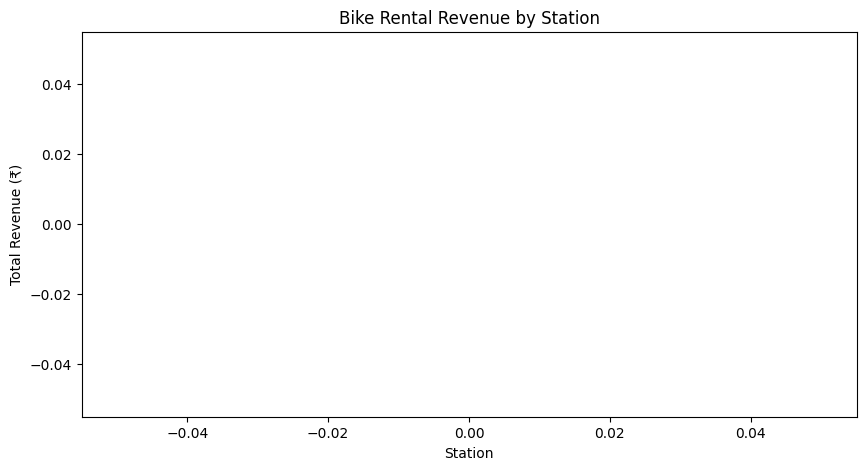

In [0]:
import matplotlib.pyplot as plt
df = spark.sql("""
    SELECT station, total_rides, total_revenue
    FROM workspace.default.bike_gold_sql
""")
pdf = df.toPandas()
plt.figure(figsize=(10, 5))
plt.bar(pdf["station"], pdf["total_revenue"])
plt.xlabel("Station")
plt.ylabel("Total Revenue (₹)")
plt.title("Bike Rental Revenue by Station")
plt.show()

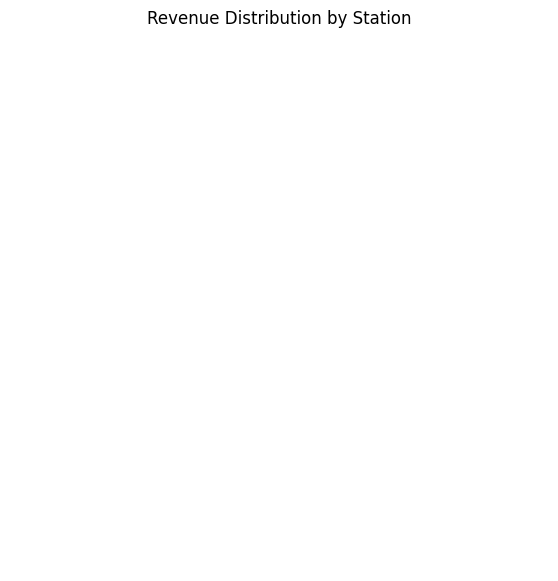

In [0]:

plt.figure(figsize=(7, 7))

plt.pie(
    pdf["total_revenue"],
    labels=pdf["station"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution by Station")
plt.show()

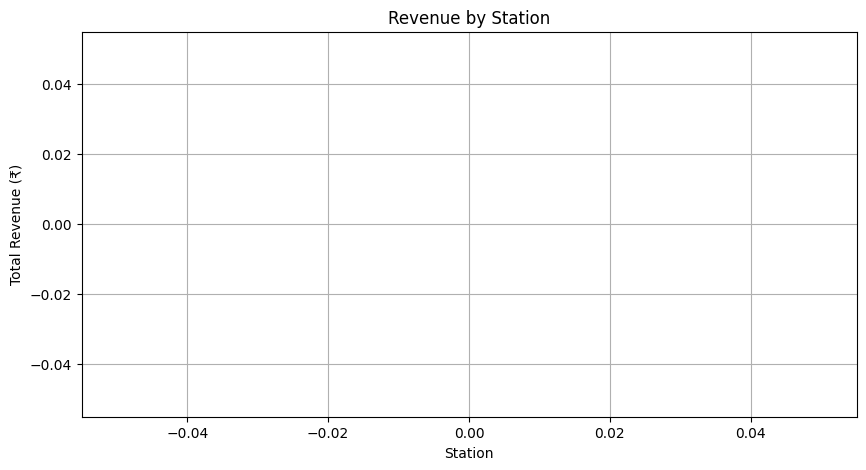

In [0]:
pdf = pdf.sort_values("station")

plt.figure(figsize=(10, 5))

plt.plot(
    pdf["station"],
    pdf["total_revenue"],
    marker="o"
)

plt.xlabel("Station")
plt.ylabel("Total Revenue (₹)")
plt.title("Revenue by Station")
plt.grid(True)
plt.show()  

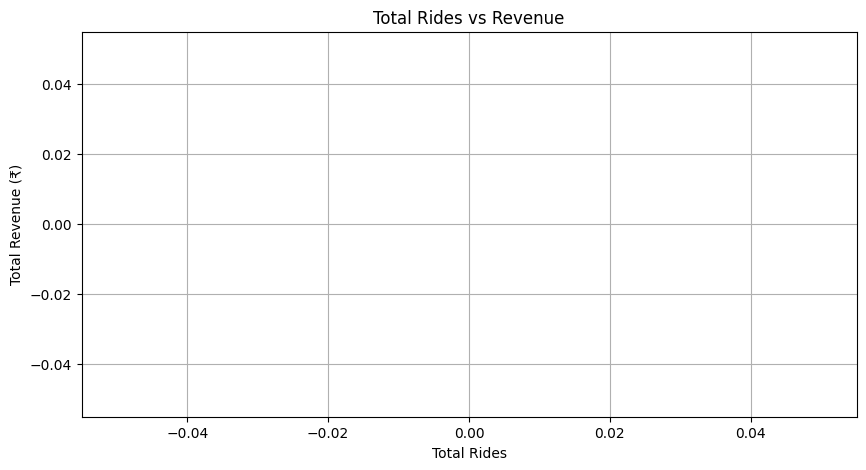

In [0]:
plt.figure(figsize=(10, 5))

plt.scatter(
    pdf["total_rides"],
    pdf["total_revenue"],
    s=100
)

for _, row in pdf.iterrows():
    plt.annotate(
        row["station"],
        (row["total_rides"], row["total_revenue"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Total Rides")
plt.ylabel("Total Revenue (₹)")
plt.title("Total Rides vs Revenue")
plt.grid(True)
plt.show()